# Deterministic Bakery Order Processing

A pure Python LangGraph workflow. It makes no LLM or external AI calls.

In [11]:
!pip -q install langgraph

In [12]:
from typing import Literal, TypedDict
from langgraph.graph import StateGraph, START, END

MENU = {
    "challah": {"price": 18, "inventory": 10},
    "sourdough": {"price": 25, "inventory": 4},
    "rugelach": {"price": 30, "inventory": 3},
    "babka": {"price": 45, "inventory": 0},
}

FALLBACK_CHAIN = ["babka", "rugelach", "sourdough", "challah"]

class State(TypedDict):
    """Public result state: exactly the six requested fields."""
    status: Literal["accepted", "rejected"]
    item: str
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]

class OrderInput(TypedDict):
    item: str
    quantity: int
    day: str
    city: str

class InternalState(TypedDict, total=False):
    """Runtime fields combine invocation inputs with public result fields."""
    item: str
    quantity: int
    day: str
    city: str
    status: Literal["accepted", "rejected"]
    delivery: Literal["pickup", "delivery"]
    total: float
    message: str
    steps: list[str]
    delivery_fee: int
    baked_goods_total: float

In [13]:
def validate(state: InternalState) -> dict:
    steps = list(state.get("steps", [])) + ["Validation"]
    item = state["item"]
    quantity = state["quantity"]
    if quantity <= 0 or item not in MENU:
        return {"status": "rejected", "message": "We couldn't understand the order.", "steps": steps}
    return {"steps": steps}

def route_after_validation(state: InternalState) -> str:
    return "end" if state.get("status") == "rejected" else "inventory"

def inventory(state: InternalState) -> dict:
    steps = list(state.get("steps", [])) + ["Inventory & Fallback"]
    requested = state["item"]
    quantity = state["quantity"]
    if MENU[requested]["inventory"] >= quantity:
        return {"steps": steps}

    # Inspect candidates after the requested item in the strict chain,
    # with at most two alternatives offered.
    start = FALLBACK_CHAIN.index(requested)
    alternatives = FALLBACK_CHAIN[start + 1 : start + 3]
    for candidate in alternatives:
        if MENU[candidate]["inventory"] >= quantity:
            return {"item": candidate, "steps": steps}

    return {"status": "rejected", "message": "Apologies, order cancelled due to lack of inventory.", "steps": steps}

def route_after_inventory(state: InternalState) -> str:
    return "end" if state.get("status") == "rejected" else "delivery"

def delivery(state: InternalState) -> dict:
    steps = list(state.get("steps", [])) + ["Delivery"]
    city = state.get("city", "")
    if city == "Jerusalem":
        return {"delivery": "delivery", "delivery_fee": 20, "steps": steps}
    return {"delivery": "pickup", "delivery_fee": 0, "steps": steps}

def pricing(state: InternalState) -> dict:
    baked_goods_total = MENU[state["item"]]["price"] * state["quantity"]
    if baked_goods_total > 150 and state["day"] != "Friday":
        baked_goods_total *= 0.85
    total = baked_goods_total + state["delivery_fee"]
    return {"baked_goods_total": baked_goods_total, "total": total, "steps": list(state.get("steps", [])) + ["Pricing"]}

def message(state: InternalState) -> dict:
    delivery = state["delivery"]
    method = "delivery to Jerusalem" if delivery == "delivery" else "pickup"
    note = " Orders from outside Jerusalem are switched to pickup." if state.get("city", "") not in ("", "Jerusalem") else ""
    total = state["total"]
    total_text = f"{total:.2f}" if total % 1 else f"{total:.0f}"
    text = (f"Thank you! Your order for {state['quantity']} {state['item']} "
            f"is confirmed for {method}. Total: ₪{total_text}." + note)
    return {"status": "accepted", "message": text, "steps": list(state.get("steps", [])) + ["Message"]}

builder = StateGraph(InternalState, input_schema=OrderInput, output_schema=State)
builder.add_node("validation", validate)
builder.add_node("inventory", inventory)
builder.add_node("delivery", delivery)
builder.add_node("pricing", pricing)
builder.add_node("message", message)
builder.add_edge(START, "validation")
builder.add_conditional_edges("validation", route_after_validation, {"end": END, "inventory": "inventory"})
builder.add_conditional_edges("inventory", route_after_inventory, {"end": END, "delivery": "delivery"})
builder.add_edge("delivery", "pricing")
builder.add_edge("pricing", "message")
builder.add_edge("message", END)
graph = builder.compile()

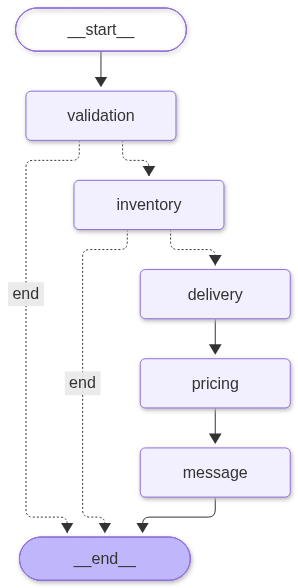

In [14]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [15]:
result = graph.invoke({"item": "babka", "quantity": 2, "day": "Thursday", "city": "Jerusalem"})
result

{'status': 'accepted',
 'item': 'rugelach',
 'delivery': 'delivery',
 'total': 80,
 'message': 'Thank you! Your order for 2 rugelach is confirmed for delivery to Jerusalem. Total: ₪80.',
 'steps': ['Validation',
  'Inventory & Fallback',
  'Delivery',
  'Pricing',
  'Message']}

In [16]:
print("--- Test 1: Invalid item ---")
print(graph.invoke({"item": "pizza", "quantity": 1, "day": "Sunday", "city": "Jerusalem"}))

print("--- Test 2: Out of stock completely ---")
print(graph.invoke({"item": "babka", "quantity": 15, "day": "Monday", "city": "Jerusalem"}))

print("--- Test 3: Fallback success + Delivery ---")
print(graph.invoke({"item": "babka", "quantity": 2, "day": "Tuesday", "city": "Jerusalem"}))

print("--- Test 4: Outside Jerusalem (Switched to pickup) ---")
print(graph.invoke({"item": "challah", "quantity": 2, "day": "Wednesday", "city": "Tel Aviv"}))

print("--- Test 5: Big order discount + Pickup ---")
print(graph.invoke({"item": "challah", "quantity": 10, "day": "Thursday", "city": ""}))

print("--- Test 6: Big order but on Friday (No discount) ---")
print(graph.invoke({"item": "sourdough", "quantity": 7, "day": "Friday", "city": "Jerusalem"}))

--- Test 1: Invalid item ---
{'status': 'rejected', 'item': 'pizza', 'message': "We couldn't understand the order.", 'steps': ['Validation']}
--- Test 2: Out of stock completely ---
{'status': 'rejected', 'item': 'babka', 'message': 'Apologies, order cancelled due to lack of inventory.', 'steps': ['Validation', 'Inventory & Fallback']}
--- Test 3: Fallback success + Delivery ---
{'status': 'accepted', 'item': 'rugelach', 'delivery': 'delivery', 'total': 80, 'message': 'Thank you! Your order for 2 rugelach is confirmed for delivery to Jerusalem. Total: ₪80.', 'steps': ['Validation', 'Inventory & Fallback', 'Delivery', 'Pricing', 'Message']}
--- Test 4: Outside Jerusalem (Switched to pickup) ---
{'status': 'accepted', 'item': 'challah', 'delivery': 'pickup', 'total': 36, 'message': 'Thank you! Your order for 2 challah is confirmed for pickup. Total: ₪36. Orders from outside Jerusalem are switched to pickup.', 'steps': ['Validation', 'Inventory & Fallback', 'Delivery', 'Pricing', 'Message